# Human Activity Recognition Using Logistic Regression, Decision Tree and Random Forest
## Introduction

Human Activity Recognition (HAR) is the process of identifying a person's physical activity using sensor data.

In this project, smartphone sensor data is analyzed to recognize different human activities.

Exploratory Data Analysis (EDA) is performed to understand the dataset and identify important patterns.

Machine learning classification models are then trained to predict the activity of a person.

The performance of different models is compared using suitable evaluation metrics.

## Problem Statement

Human Activity Recognition aims to identify a person's activity using smartphone sensor data.

The objective of this project is to analyze sensor-based features using EDA.

Machine learning models are used to classify different human activities.

The performance of different classification models is compared.

The best-performing model is evaluated using suitable performance metrics.

## 1. Import Required Libraries

The following Python libraries are used in this project:

- Pandas – for data loading and data manipulation
- NumPy – for numerical operations
- Matplotlib – for data visualization
- Seaborn – for statistical visualization
- Scikit-learn – for preprocessing, machine learning models, and evaluation

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load Dataset

The Human Activity Recognition dataset is stored in CSV format.

The dataset is loaded using Pandas for further analysis.

In [3]:
df = pd.read_csv("HAR_dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


## 3. Display Dataset

The first few rows of the dataset are displayed to understand its structure and the type of information available.

In [4]:
df.head()

,subject,activity_id,activity,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
0,1,5,STANDING,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,...,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,1,5,STANDING,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,...,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,1,5,STANDING,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,...,0.414503,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118
3,1,5,STANDING,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,...,0.404573,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663
4,1,5,STANDING,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,...,0.087753,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892


## 4. Dataset Shape

The shape of the dataset shows the total number of rows and columns available for analysis.

In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 10299
Number of columns: 564


## 5. Dataset Information

The information of the dataset is checked to understand the data types, number of columns, and memory usage.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10299 entries, 0 to 10298
Columns: 564 entries, subject to angle(Z,gravityMean)
dtypes: float64(561), int64(2), object(1)
memory usage: 44.3+ MB


## 6. Column Names

The column names are displayed to understand the sensor features and target-related columns.

In [7]:
print(df.columns)

Index(['subject', 'activity_id', 'activity', 'tBodyAcc-mean()-X',
       'tBodyAcc-mean()-Y', 'tBodyAcc-mean()-Z', 'tBodyAcc-std()-X',
       'tBodyAcc-std()-Y', 'tBodyAcc-std()-Z', 'tBodyAcc-mad()-X',
       ...
       'fBodyBodyGyroJerkMag-meanFreq()', 'fBodyBodyGyroJerkMag-skewness()',
       'fBodyBodyGyroJerkMag-kurtosis()', 'angle(tBodyAccMean,gravity)',
       'angle(tBodyAccJerkMean),gravityMean)',
       'angle(tBodyGyroMean,gravityMean)',
       'angle(tBodyGyroJerkMean,gravityMean)', 'angle(X,gravityMean)',
       'angle(Y,gravityMean)', 'angle(Z,gravityMean)'],
      dtype='object', length=564)


## 7. Statistical Summary

Descriptive statistics are used to understand the distribution of numerical sensor features.

Measures such as mean, standard deviation, minimum, and maximum values are analyzed.

In [8]:
df.describe().head(20)

,subject,activity_id,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
count,10299.000000,10299.000000,10299.000000,10299.000000,10299.000000,10299.000000,10299.000000,10299.000000,10299.000000,10299.000000,...,10299.000000,10299.000000,10299.000000,10299.000000,10299.000000,10299.000000,10299.000000,10299.000000,10299.000000,10299.000000
mean,16.146422,3.624624,0.274347,-0.017743,-0.108925,-0.607784,-0.510191,-0.613064,-0.633593,-0.525697,...,0.126708,-0.298592,-0.617700,0.007705,0.002648,0.017683,-0.009219,-0.496522,0.063255,-0.054284
std,8.679067,1.743695,0.067628,0.037128,0.053033,0.438694,0.500240,0.403657,0.413333,0.484201,...,0.245443,0.320199,0.308796,0.336591,0.447364,0.616188,0.484770,0.511158,0.305468,0.268898
min,1.000000,1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
25%,9.000000,2.000000,0.262625,-0.024902,-0.121019,-0.992360,-0.976990,-0.979137,-0.993293,-0.977017,...,-0.019481,-0.536174,-0.841847,-0.124694,-0.287031,-0.493108,-0.389041,-0.817288,0.002151,-0.131880
50%,17.000000,4.000000,0.277174,-0.017162,-0.108596,-0.943030,-0.835032,-0.850773,-0.948244,-0.843670,...,0.136245,-0.335160,-0.703402,0.008146,0.007668,0.017192,-0.007186,-0.715631,0.182028,-0.003882
75%,24.000000,5.000000,0.288354,-0.010625,-0.097589,-0.250293,-0.057336,-0.278737,-0.302033,-0.087405,...,0.288960,-0.113167,-0.487981,0.149005,0.291490,0.536137,0.365996,-0.521503,0.250790,0.102970
max,30.000000,6.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## 8. Missing Value Analysis

Missing values are checked to determine whether the dataset contains incomplete observations.

In [9]:
missing_values = df.isnull().sum()

print("Total missing values:", missing_values.sum())

Total missing values: 0


## 9. Duplicate Analysis

Duplicate rows are checked to identify repeated observations in the dataset.

In [10]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


## 10. Activity Distribution

The distribution of different human activities is analyzed to understand how many observations belong to each activity.

In [11]:
activity_counts = df["activity"].value_counts()

print(activity_counts)

activity
LAYING                1944
STANDING              1906
SITTING               1777
WALKING               1722
WALKING_UPSTAIRS      1544
WALKING_DOWNSTAIRS    1406
Name: count, dtype: int64


## 11. Activity Visualization

A count plot is used to visualize the number of observations for each human activity.

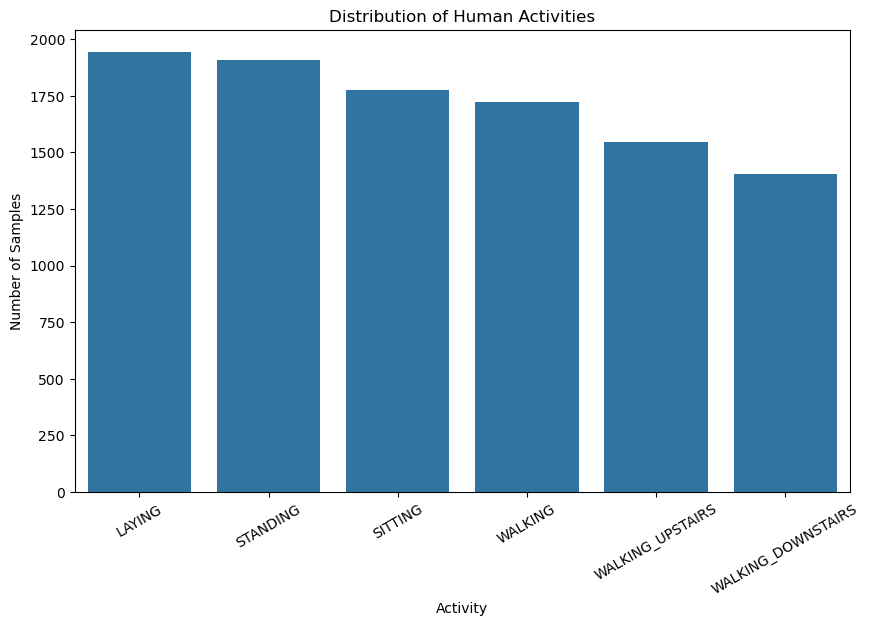

In [12]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="activity",
    order=df["activity"].value_counts().index
)

plt.title("Distribution of Human Activities")
plt.xlabel("Activity")
plt.ylabel("Number of Samples")
plt.xticks(rotation=30)

plt.show()

## 12. Activity Percentage

The percentage of observations belonging to each activity is calculated to understand the relative distribution of the classes.

In [13]:
activity_percentage = (
    df["activity"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(activity_percentage)

activity
LAYING                18.88
STANDING              18.51
SITTING               17.25
WALKING               16.72
WALKING_UPSTAIRS      14.99
WALKING_DOWNSTAIRS    13.65
Name: proportion, dtype: float64


## 13. Activity Percentage Visualization

A pie chart is used to visualize the percentage distribution of different human activities.

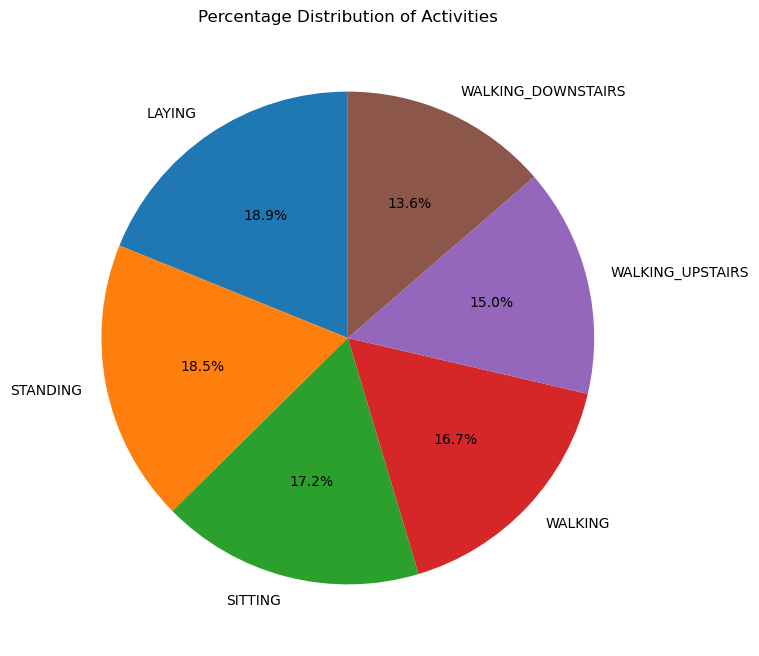

In [14]:
plt.figure(figsize=(8, 8))

plt.pie(
    activity_percentage,
    labels=activity_percentage.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Percentage Distribution of Activities")

plt.show()

## 14. Subject Distribution

The number of observations contributed by each subject is analyzed to understand the distribution of data among participants.

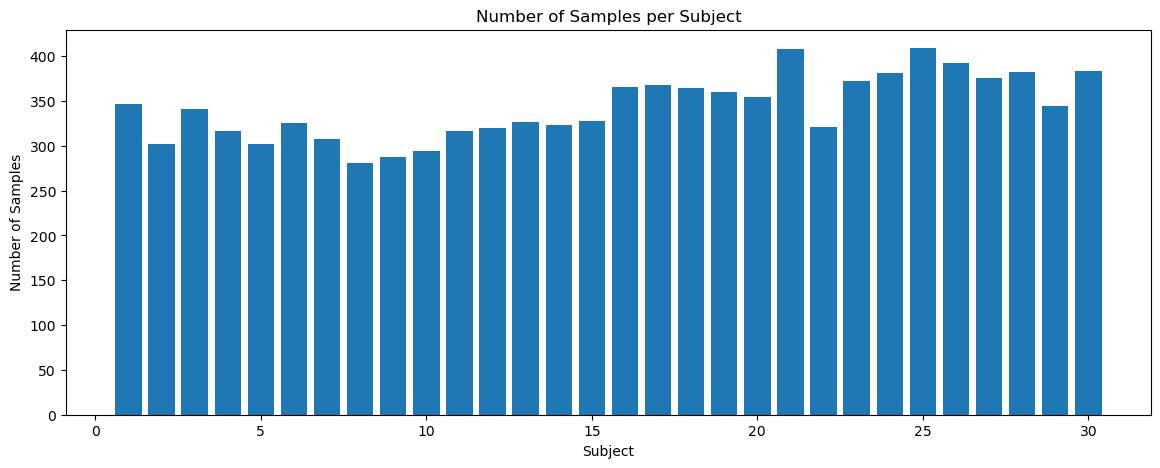

In [15]:
subject_counts = df["subject"].value_counts().sort_index()

plt.figure(figsize=(14, 5))

plt.bar(
    subject_counts.index,
    subject_counts.values
)

plt.title("Number of Samples per Subject")
plt.xlabel("Subject")
plt.ylabel("Number of Samples")

plt.show()

## 15. Feature Analysis

The dataset contains a large number of sensor-derived features.

A small set of representative features is selected for visualization and exploratory analysis.

In [16]:
selected_features = [
    "tBodyAcc-mean()-X",
    "tBodyAcc-mean()-Y",
    "tBodyAcc-mean()-Z",
    "tBodyAcc-std()-X",
    "tBodyAcc-std()-Y",
    "tBodyAcc-std()-Z",
    "tGravityAcc-mean()-X",
    "tGravityAcc-mean()-Y",
    "tGravityAcc-mean()-Z",
    "tBodyGyro-mean()-X",
    "tBodyGyro-mean()-Y",
    "tBodyGyro-mean()-Z"
]

print("Selected Features:")
print(*selected_features, sep="\n")

Selected Features:
tBodyAcc-mean()-X
tBodyAcc-mean()-Y
tBodyAcc-mean()-Z
tBodyAcc-std()-X
tBodyAcc-std()-Y
tBodyAcc-std()-Z
tGravityAcc-mean()-X
tGravityAcc-mean()-Y
tGravityAcc-mean()-Z
tBodyGyro-mean()-X
tBodyGyro-mean()-Y
tBodyGyro-mean()-Z


## 16. Feature Distribution

Histograms are used to examine the distribution of selected sensor features.

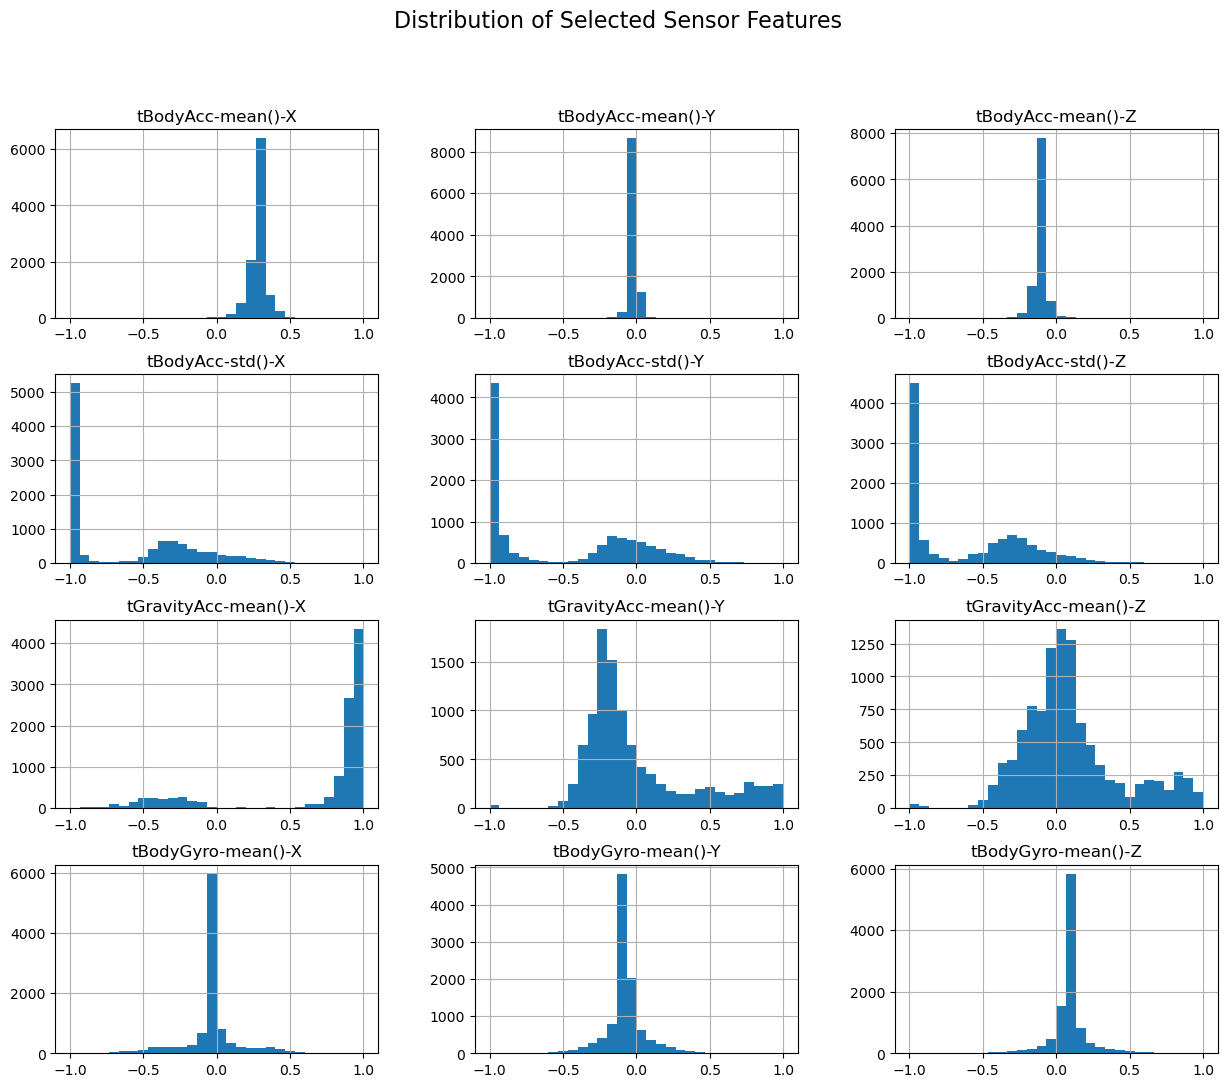

In [17]:
df[selected_features].hist(
    figsize=(15, 12),
    bins=30
)

plt.suptitle(
    "Distribution of Selected Sensor Features",
    fontsize=16
)

plt.show()

## 17. Boxplot Analysis

A boxplot is used to compare the distribution of a selected sensor feature across different human activities.

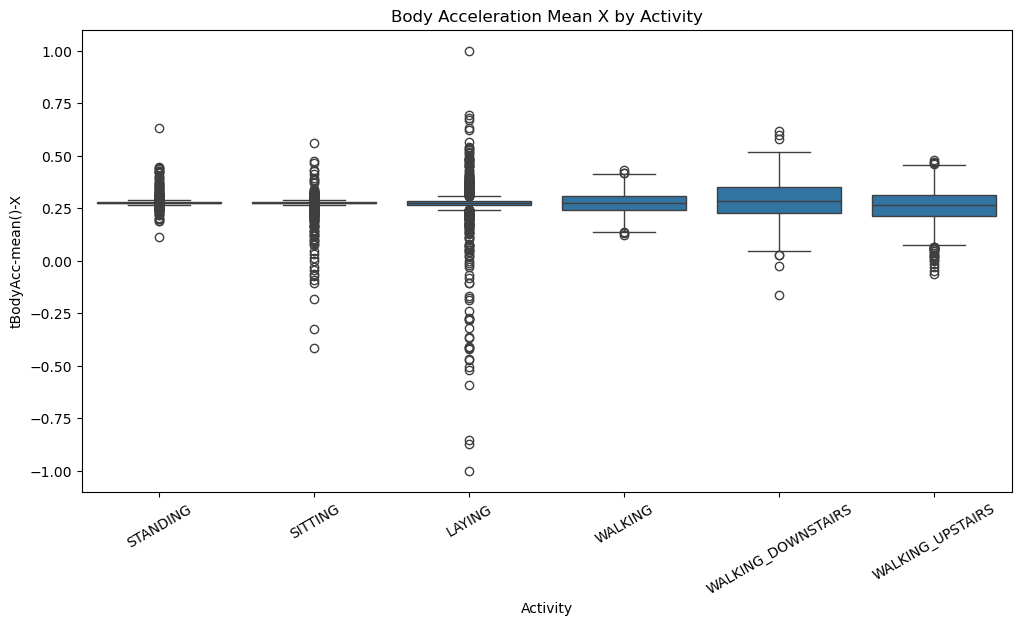

In [18]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="activity",
    y="tBodyAcc-mean()-X"
)

plt.title("Body Acceleration Mean X by Activity")
plt.xlabel("Activity")
plt.ylabel("tBodyAcc-mean()-X")
plt.xticks(rotation=30)

plt.show()

## 18. Correlation Analysis

Correlation analysis is performed to understand the relationship between selected sensor features.

A heatmap is used to visualize the correlation values.

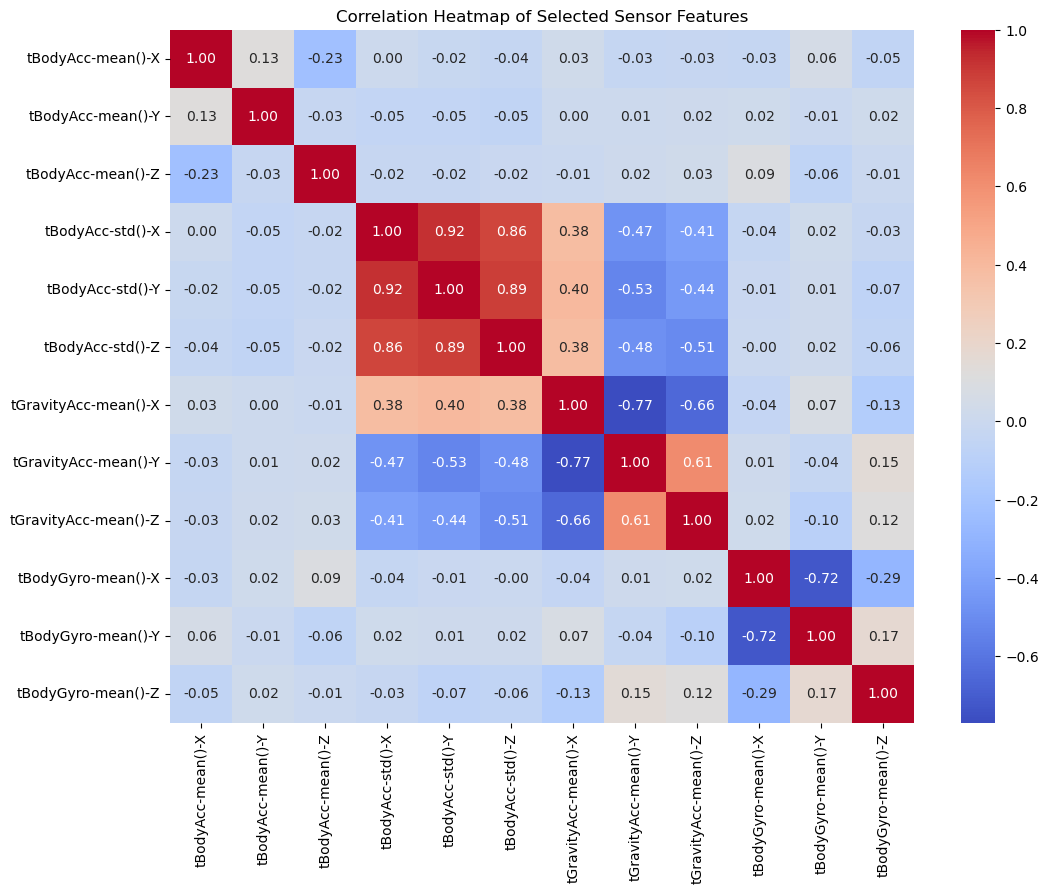

In [19]:
correlation = df[selected_features].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap of Selected Sensor Features")

plt.show()

## 19. Dynamic and Static Activity Analysis

The activities are grouped into dynamic and static categories.

Walking-related activities are considered dynamic, while the remaining activities are grouped as static.

In [20]:
dynamic_activities = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS"
]

df["activity_type"] = df["activity"].apply(
    lambda x: "Dynamic"
    if x in dynamic_activities
    else "Static"
)

print(df["activity_type"].value_counts())

activity_type
Static     5627
Dynamic    4672
Name: count, dtype: int64


## 20. Dynamic vs Static Activities

A count plot is used to compare the number of dynamic and static activity observations.

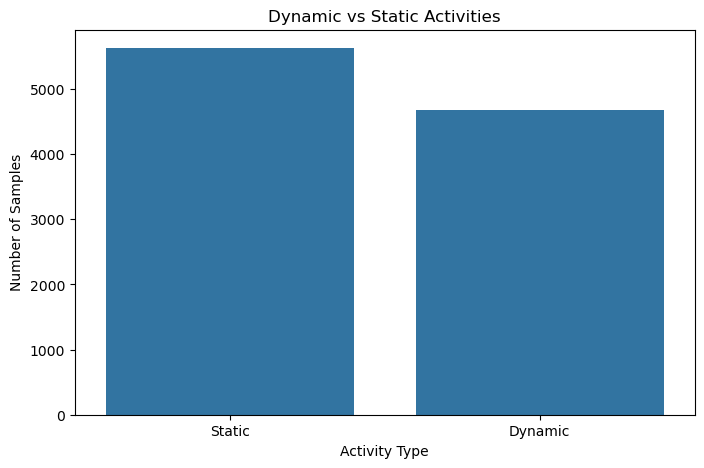

In [21]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="activity_type"
)

plt.title("Dynamic vs Static Activities")
plt.xlabel("Activity Type")
plt.ylabel("Number of Samples")

plt.show()

## 21. Data Preparation for Machine Learning

The activity column is used as the target variable.

The subject, activity ID, activity name, and activity type columns are excluded from the input features.

The remaining sensor features are used for model training.

In [22]:
X = df.drop(
    columns=[
        "activity",
        "activity_id",
        "subject",
        "activity_type"
    ]
)

y = df["activity"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (10299, 561)
Target shape: (10299,)


## 22. Train-Test Split

The dataset is divided into training and testing sets.

The training data is used to build the models, while the testing data is used to evaluate their performance.

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (8239, 561)
Testing data: (2060, 561)


## 23. Logistic Regression

Logistic Regression is used as a baseline classification model.

StandardScaler is used to scale the sensor features before applying Logistic Regression.

In [24]:
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        random_state=42
    )
)

lr_model.fit(X_train, y_train)
pred_lr = lr_model.predict(X_test)
acc_lr = accuracy_score(
    y_test,
    pred_lr
)
print(
    "Logistic Regression Accuracy:",
    round(acc_lr * 100, 2),
    "%"
)

Logistic Regression Accuracy: 98.54 %


## 24. Decision Tree

Decision Tree is a classification algorithm that uses a series of decision rules to classify different human activities.

In [25]:
dt_model = DecisionTreeClassifier(
    random_state=42
)
dt_model.fit(
    X_train,
    y_train
)
pred_dt = dt_model.predict(X_test)
acc_dt = accuracy_score(
    y_test,
    pred_dt
)
print(
    "Decision Tree Accuracy:",
    round(acc_dt * 100, 2),
    "%"
)

Decision Tree Accuracy: 93.69 %


## 25. Random Forest

Random Forest is an ensemble classification algorithm that combines multiple decision trees.

It is also used to identify the importance of different sensor features.

In [26]:
rf_model = RandomForestClassifier(
    n_estimators=150,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

pred_rf = rf_model.predict(X_test)

acc_rf = accuracy_score(
    y_test,
    pred_rf
)

print(
    "Random Forest Accuracy:",
    round(acc_rf * 100, 2),
    "%"
)

Random Forest Accuracy: 98.2 %


## 26. Model Comparison

The three classification models are compared using their test accuracy.

The model with the highest accuracy in the actual results is identified.

In [27]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        acc_lr,
        acc_dt,
        acc_rf
    ]
})

results["Accuracy (%)"] = (
    results["Accuracy"] * 100
).round(2)

results

,Model,Accuracy,Accuracy (%)
0,Logistic Regression,0.985437,98.54
1,Decision Tree,0.936893,93.69
2,Random Forest,0.982039,98.20


## 27. Model Accuracy Visualization

A bar graph is used to visually compare the accuracy of the three classification models.

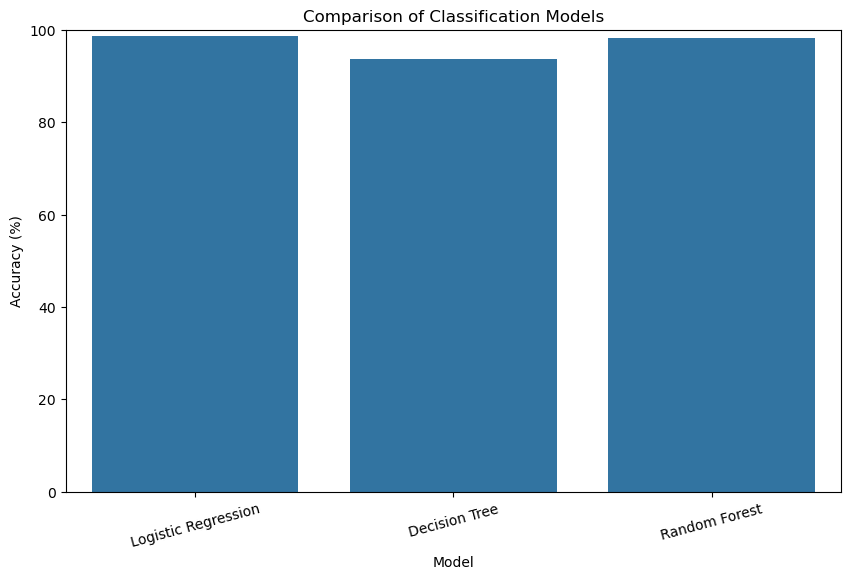

In [28]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy (%)"
)

plt.title("Comparison of Classification Models")
plt.xlabel("Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.xticks(rotation=15)

plt.show()

## 28. Best Model

The model with the highest test accuracy is selected as the best-performing model for this dataset.

In [29]:
best_row = results.loc[
    results["Accuracy"].idxmax()
]

best_model_name = best_row["Model"]
best_accuracy = best_row["Accuracy (%)"]

print("Best Model:", best_model_name)
print("Best Accuracy:", best_accuracy, "%")

Best Model: Logistic Regression
Best Accuracy: 98.54 %


## 29. Classification Report

The classification report provides precision, recall, and F1-score for each activity class.

These metrics provide a more detailed evaluation of the selected model.

In [30]:
model_predictions = {
    "Logistic Regression": pred_lr,
    "Decision Tree": pred_dt,
    "Random Forest": pred_rf
}

best_predictions = model_predictions[
    best_model_name
]

print("Classification Report")

print(
    classification_report(
        y_test,
        best_predictions
    )
)

Classification Report
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       389
           SITTING       0.97      0.96      0.96       356
          STANDING       0.96      0.97      0.97       381
           WALKING       0.99      1.00      0.99       344
WALKING_DOWNSTAIRS       1.00      1.00      1.00       281
  WALKING_UPSTAIRS       1.00      0.99      0.99       309

          accuracy                           0.99      2060
         macro avg       0.99      0.99      0.99      2060
      weighted avg       0.99      0.99      0.99      2060



## 30. Confusion Matrix

A confusion matrix is used to compare the actual activities with the activities predicted by the selected model.

It helps identify correctly and incorrectly classified activities.

Confusion Matrix:
[[389   0   0   0   0   0]
 [  0 341  14   0   0   1]
 [  0  10 371   0   0   0]
 [  0   0   0 344   0   0]
 [  0   0   0   1 280   0]
 [  0   0   0   3   1 305]]


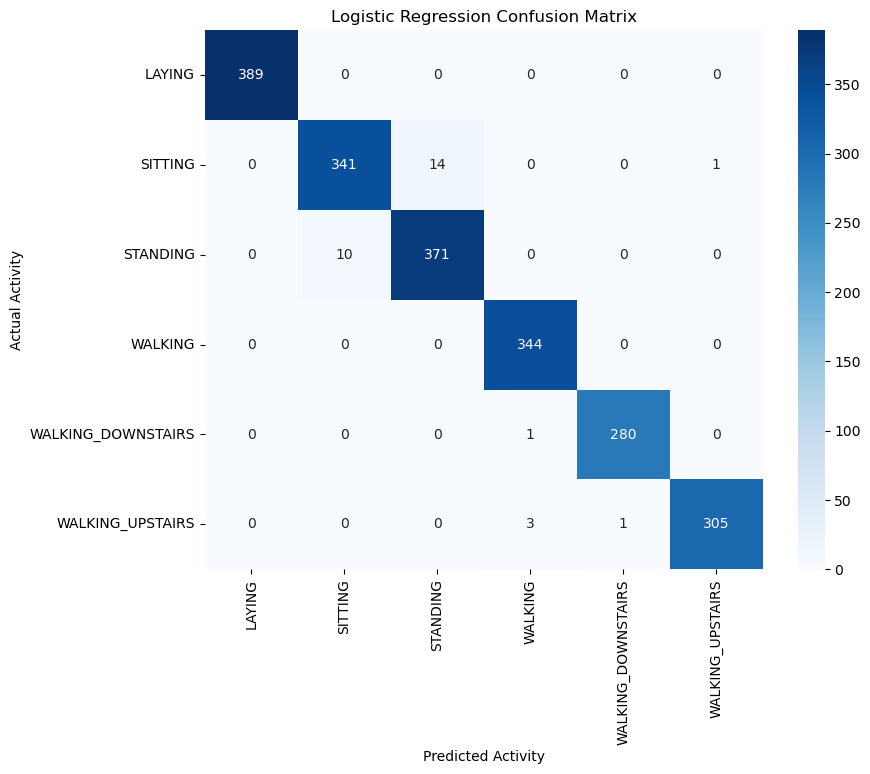

In [31]:
cm = confusion_matrix(
    y_test,
    best_predictions
)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title(
    f"{best_model_name} Confusion Matrix"
)

plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")

plt.show()

## 31. Feature Importance

Random Forest provides feature importance values.

These values help identify which sensor features contributed more to the classification process.

In [32]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 20 Important Features:")

print(
    feature_importance
    .head(20)
    .to_string(index=False)
)

Top 20 Important Features:
                          Feature  Importance
             tGravityAcc-mean()-X    0.033026
             angle(X,gravityMean)    0.029668
           tGravityAcc-energy()-X    0.028093
              tGravityAcc-max()-X    0.024425
              tGravityAcc-min()-Y    0.023460
              tGravityAcc-min()-X    0.023255
             tGravityAcc-mean()-Y    0.022625
             angle(Y,gravityMean)    0.020022
              tGravityAcc-max()-Y    0.018993
           tGravityAcc-energy()-Y    0.013124
             tBodyAccJerk-std()-X    0.011240
                tBodyAccMag-std()    0.010948
            tBodyGyroJerk-iqr()-Z    0.010851
               tBodyAccJerk-sma()    0.009812
             fBodyAccJerk-max()-X    0.009653
             angle(Z,gravityMean)    0.009620
fBodyAccJerk-bandsEnergy()-1,16_1    0.009501
             fBodyAccMag-energy()    0.009468
              tGravityAcc-min()-Z    0.009468
        tGravityAcc-arCoeff()-Y,2    0.009250


## 32. Important Features Visualization

The top 20 important sensor features are visualized using a bar graph.

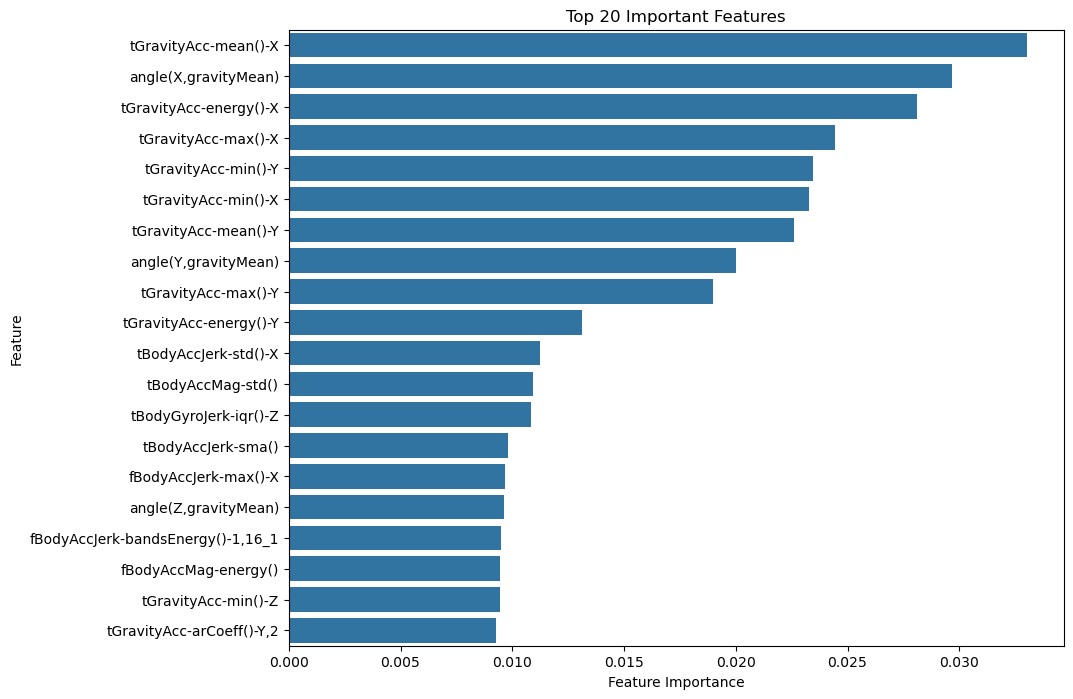

In [33]:
top_features = feature_importance.head(20)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Important Features")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.show()

## 33. Final Model Summary

The performance of all three classification models is summarized below.

The best-performing model is selected based on its actual test accuracy.

In [34]:
print("=" * 50)
print("FINAL MODEL SUMMARY")
print("=" * 50)

print(
    "Logistic Regression:",
    round(acc_lr * 100, 2),
    "%"
)

print(
    "Decision Tree:",
    round(acc_dt * 100, 2),
    "%"
)

print(
    "Random Forest:",
    round(acc_rf * 100, 2),
    "%"
)

print("-" * 50)

print("Best Model:", best_model_name)
print("Best Accuracy:", best_accuracy, "%")

print("=" * 50)

FINAL MODEL SUMMARY
Logistic Regression: 98.54 %
Decision Tree: 93.69 %
Random Forest: 98.2 %
--------------------------------------------------
Best Model: Logistic Regression
Best Accuracy: 98.54 %


## 34. Save Results

The model comparison results and feature importance values are saved as CSV files for future reference.

In [35]:
results.to_csv(
    "HAR_model_comparison_results.csv",
    index=False
)

feature_importance.to_csv(
    "HAR_feature_importance.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!


## Real-Time Human Activity Prediction Example

The trained best-performing model is used to predict the activity of an unseen smartphone sensor sample.

In [36]:
# Select one unseen sample from the test data
sample = X_test.iloc[[0]]

# Predict the activity
prediction = rf_model.predict(sample)

print("Predicted Activity:", prediction[0])

Predicted Activity: STANDING


# Conclusion

In this project, Human Activity Recognition was performed using smartphone sensor data and machine learning techniques.

The dataset was analyzed using Exploratory Data Analysis to understand activity distribution, sensor features, missing values, duplicate values, and feature relationships.

Logistic Regression, Decision Tree, and Random Forest classification models were implemented and compared using test accuracy.

The best-performing model was selected based on the actual test results.

The selected model was further evaluated using precision, recall, F1-score, and a confusion matrix.

Overall, the project demonstrates how machine learning can be used to classify human activities using smartphone sensor data.